# Fundamentos de Ciencia de Datos - FCEx - UNICEN

# Unidad 8: Análisis multivariado con métodos de regresión

## Clase Práctica 9: Regresión lineal

Este Colab corresponde a la novena clase práctica del curso Fundamentos de Ciencia de Datos, que se dicta en el 4to año de la carrera de Ingeniería de Sistemas de la Facultad de Ciencias Exactas de la UNICEN.

La clase de hoy se enfoca en regresión lineal. Pero no la vamos a abordar desde mi perspectiva preferida (la de machine learning), si no desde la perspectiva del análisis multivariado. Vamos a usar regresión lineal como una herramienta para entender vínculos entre variables independientes de un dataset contra una variable respuesta de nuestra elección. Vamos a empezar mirando un ejemplo muy simple, con una única variable, y después avanzaremos hacia el uso de múltiples variables en simultáneo, para estudiar qué efecto tiene integrarlas. Y de paso vamos a reforzar algunos conceptos y traer algunos otros que quizá no vieron en la teoría, pero que son súper útiles para trabajar en estos temas.

Ya en la clase que viene vamos a movernos más para la parte de machine learning, viendo cómo estos mismos principios pueden ayudarnos a generar modelos con capacidades predictivas.


## 1 - Accedemos a los datos

Vamos a trabajar nuevamente con esta idea de análisis inmobiliario (lo que en inglés se conoce como Real State). Pero en vez de hacerlo con los datos demográficos y de costo de las propiedades de Boston, que tienen esas variables polemiquísimas como el número de personas afroamericanas de cada distrito, vamos a hacerlo con datos del Estado de California en EE.UU, provenientes de un conjunto también muy conocido, el [California Housing Dataset](https://www.kaggle.com/camnugent/california-housing-prices), disponible en Sklearn.

Para los que no lo recuerden, California es uno de los estados más grandes de EE.UU., ubicado en la costa oeste. Linda con México al sur, y es donde están las compañías de innovación en tecnología más importantes del mundo (Google, Meta, Apple, Microsoft, etc.). Acá les dejo el mapa de EE.UU. para que se orienten de dónde estamos hablando.

![](https://upload.wikimedia.org/wikipedia/commons/d/dd/Map_of_USA_CA.svg)

Arranquemos como de costumbre accediendo a los datos y mirándolos un poquito. Para eso vamos a usar la rutina de acceso que ya viene disponible en Sklearn, que nos facilita la vida y nos simplifica tener que instalar el ```wget``` y hacer descargas.

In [ ]:
from sklearn import datasets

# esta instrucción descarga el dataset usando sklearn, en formato de dataframe de pandas
dataset = datasets.fetch_california_housing(as_frame=True)

# el resultado es un diccionario, que en el campo DESCR trae la descripción del dataset
print(dataset["DESCR"])

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

Como verán, el conjunto de datos es bastante antiguo (bueno, antiguo no, tiene mi edad, así que es súper joven), pero para lo que queremos hacer, sirve.

Observen que en su descripción nos dice que cuenta con 20.640 instancias, cada una de las cuales describe a un bloque urbano (que es la unidad mínima utilizada en los censos de EE.UU.) mediante 8 atributos numéricos, y un valor de variable respuesta u objetivo, que corresponde a la mediana de valores de las casas dentro de ese distrito, expresada en cientos de miles de dólares.

En general, van a ver que siempre que trabajen con datos, el "nombre" que se le de al conjunto medio que te va a buchonear qué es lo que se espera hacer con el conjunto: el dataset que les compartimos para el trabajo especial sobre calidad de vino, claramente quiere que analicemos los factores que afectan a la calidad del vino; en el de calidad del agua, lo mismo; en el de datos musicales, seguramente el punto de interés tenga que ver con qué factores hacen populares a las distintas canciones... En este caso, entonces, ya saber que el precio de las casas es una variable respuesta, nos está indicando la dirección en la que tendremos que ir.

Antes de continuar, analicemos las variables independientes y la variable respuesta, para ver qué tipo de dato tienen asociado, si hay nulos (aunque en la descripción ya vimos que no los hay), etc:

In [ ]:
print("Información sobre los atributos:")
print(dataset["data"].info())
print("\n")
print("Información sobre la variable objetivo:")
print(dataset["target"].info())

Información sobre los atributos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
dtypes: float64(8)
memory usage: 1.3 MB
None


Información sobre la variable objetivo:
<class 'pandas.core.series.Series'>
RangeIndex: 20640 entries, 0 to 20639
Series name: MedHouseVal
Non-Null Count  Dtype  
--------------  -----  
20640 non-null  float64
dtypes: float64(1)
memory usage: 161.4 KB
None


Confirmada la no existencia de valores nulos, podríamos graficar los histogramas asociados a cada valor, así entendemos un poco mejor cómo se distribuyen y qué particulares tiene cada variable:

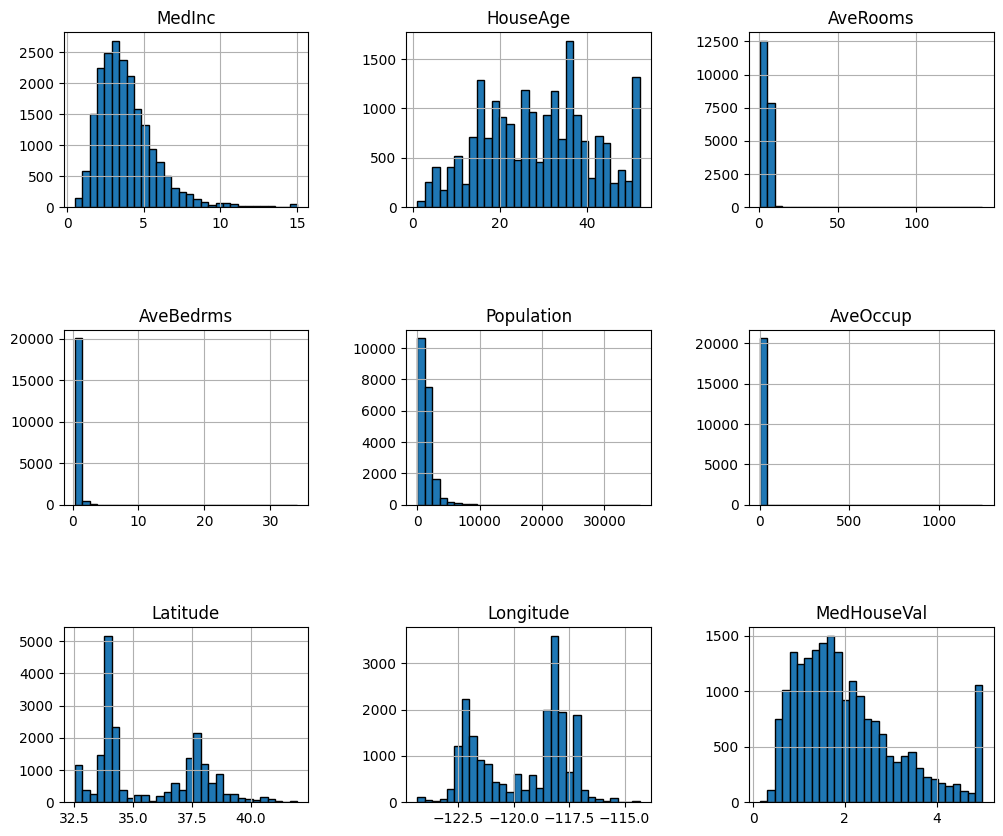

In [ ]:
import matplotlib.pyplot as plt

# construimos una serie de histogramas mostrando la distribución de las features
dataset.frame.hist(figsize=(12, 10), bins=30, edgecolor="black")
plt.subplots_adjust(hspace=0.7, wspace=0.4)

Observemos las variables de manera individual:
- ```MedInc``` tiene un sesgo pronunciado hacia valores bajos, lo que a priori nos está diciendo que no respeta una distribución normal.
- ```HouseAge```, por el contrario, se parece un poco más a una distribución normal, aunque algo ruidosa, con algunos puntos que suben bastante más.
- ```AveRooms```, ```AveBedrms``` y ```AveOccup``` parecen tener ocurrencias sobre todo en valores bajos, pero deben presentar algún tipo de outlier, porque el eje X está estirado hacia valores altos. Esto tiene sentido si observamos la descripción del dataset, donde se indica que el número promedio de habitaciones y dormitorios está dado por hogar, y que puede pasar que veamos valores  grandes en grupos de bloques con pocos hogares y muchas casas vacías, como en los complejos turísticos.
- ```Population``` muestra una frecuencia alta en torno a valores de población bajos, pero también se observa que puede llegar a haber algún outlier alto, por la forma del eje X.
- ```Latitude``` y ```Longitude``` tenen un comportamiento bimodal (hay dos valores bien definidos en cada distribución como los más frecuentes). Esto puede indicarnos que muchos bloques pueden haber sido censados en el mismo nucleo urbano, y que por ende aparezcan con más frecuencia en el dataset; o, simplemente, puede ser un indicador de que existan regiones muy pobladas en el estado de California.
- ```MedHouseVal``` tiene también un sesgo hacia la izquierda, y un pico de frecuencia en torno a los valores más altos de las casas.

Para complementar este análisis gráfico, chusmeemos las estadísticas de cada variable:

In [ ]:
# usamos el método describe() de los dataframes para resumir las muestras
dataset.frame.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


Nuevamente miremos lo que ocurre con la variables:

- ```MedInc``` tiene el 75% de los datos menor a 4.8, y vemos que hay un máximo en 15, que correspondería a las regiones de mayores ingresos. Por la forma en la gráfica estos últimos valores no parecerían ser muy frecuentes.
- ```HouseAge``` se ve que efectivamente tiene una pinta bastante normal, con la mediana prácticamente coincidiendo con la media y los 3 desvíos a izquierda y derecha "contenidos".
- ```AveRooms```, ```AveBedrms```, ```Population``` y ```AveOccup```, como era de esperar, tienen valores máximos muy altos, que claramente representan los outliers del conjunto.
- ```Latitude```, ```Longitude``` no parecen presentar mayores inconvenientes.
- ```MedHouseVal```, por su parte, muestra claramente la presencia de algún outlier en el valor máximo.

Con este análisis hecho, ya podríamos empezar a tejer nuestras primeras hipótesis.


## 2 - Construyamos algunas hipótesis en torno a nuestra variable objetivo

Como dijimos antes, tenemos bastante spoileado que lo que más nos va a interesar acá es estudiar la variable objetivo ```MedHouseVal```, así que vamos a intentar trazar alguna hipótesis a partir de lo que observemos en un primer análisis exploratorio.

Lo primero que se me ocurre es hacer algo de análisis bivariado. Hagámoslo de forma completa sobre todo el conjunto, pero prestemos particular atención a la atadura que pueda llegar a existir entre los atributos de las casas y la variable objetivo.

Empecemos, entonces, con una matriz de correlación:

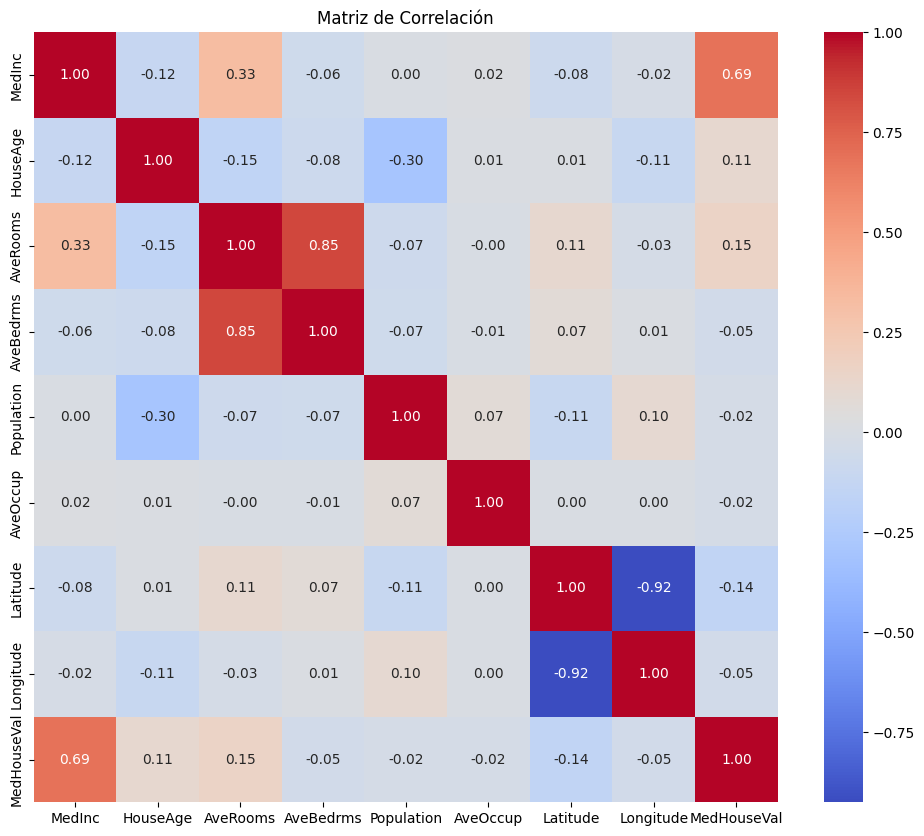

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# calculamos la matriz de correlación
correlation_matrix = dataset.frame.corr()
# la graficamos con un mapa de calor
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación')
plt.show()

Antes de estudiar las correlaciones con la variable respuesta, analicemos un poco otras que nos llaman la atención:

- Vemos que ```AveRooms```y ```AveBedrms``` tienen una correlación alta. Esto tiene sentido, si consideramos que los lugares con muchas habitaciones probablemente también tengan varios dormitorios.
- ```Latitude``` y ```Longitude``` tienen una correlación inversa muy pronunciada. Si observamos los signos de la variable ```Longitude```, vamos a ver que todos los valores son negativos (porque estamos al oeste del meridiano de Greenwitch). Entonces la correlación inversa en realidad está "corrigiendo" el signo del atributo, y nos está diciendo que hay una relación entre ambos valores bastante importante (que puede indicar concentración de centros urbanos, como vimos en los histogramas).

Las demás correlaciones se observan todas bastante bajas, por lo que a priori no vemos nada que parezca mostrarnos alguna relación adicional que revista importancia. Ahora, ¿qué pasa con nuestra variable respuesta? Hagamos un gráfico de barras mostrando solamente esas correlaciones:

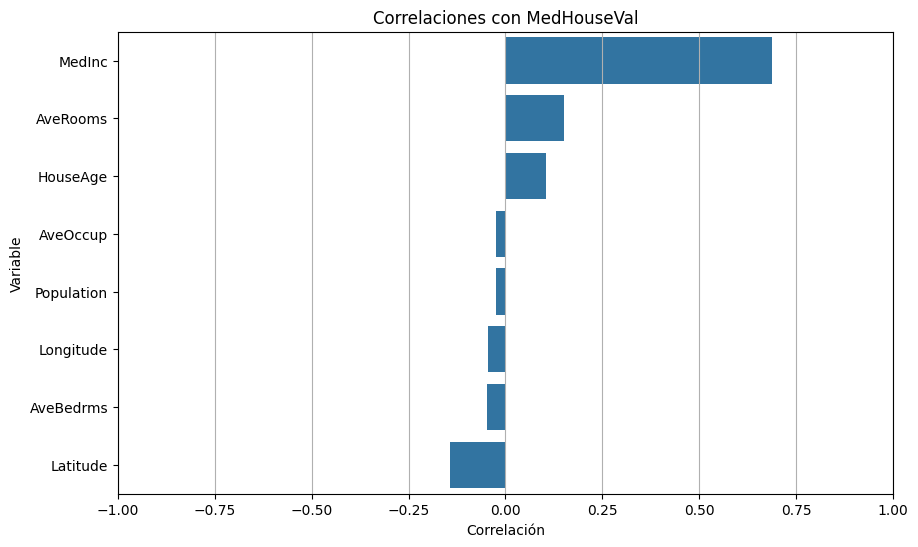

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Selecciona solo las correlaciones con MedHouseVal
medhouseval_correlations = correlation_matrix['MedHouseVal'].drop('MedHouseVal')

# Ordena las correlaciones de mayor a menor
sorted_correlations = medhouseval_correlations.sort_values(ascending=False)

# Crea un gráfico de barras para visualizar las correlaciones
plt.figure(figsize=(10, 6))
plt.grid(True)
sns.barplot(x=sorted_correlations.values, y=sorted_correlations.index)
plt.title('Correlaciones con MedHouseVal')
plt.xlabel('Correlación')
plt.ylabel('Variable')
plt.xlim([-1, 1])
plt.show()

Vemos que la principal relación que se observa es entre ```MedHouseVal```y ```MedInc```, y que todas las demás son particularmente bajas.

Todo parece indicar que cuando la media de ingresos de una región es más alta, los precios de las casas parecieran también ser más altos. Construyamos, entonces, esa hipótesis: **¿puedo predecir el valor de una casa a partir de la media de ingresos en esa región**. Vamos a validarla.

## 2 - ¿Podemos predecir MedHouseVal sólamente usando MedInc?

El orden que normalmente seguimos para estudiar una hipótesis es siempre el mismo: la construimos con un análisis exploratorio inicial del dataset, y luego profundizamos un poco más empleando las técnicas que conocemos. Arranquemos por el análisis exploratorio para entender los fenómenos que pueden estar ocurriendo en las relaciones entre estas variables, y luego pasemos sí al uso de la regresión lineal para estudiarlas más en detalle.

### 2.1 - Análisis exploratorio

Ya vimos una correlación relativamente alta entre ```MedInc``` (nuestra variable independiente) y ```MedHouseVal``` (nuestra variable dependiente). Se cae de maduro, entonces, que tendríamos que usar un scatter plot para ver gráficamente la relación entre las dos:

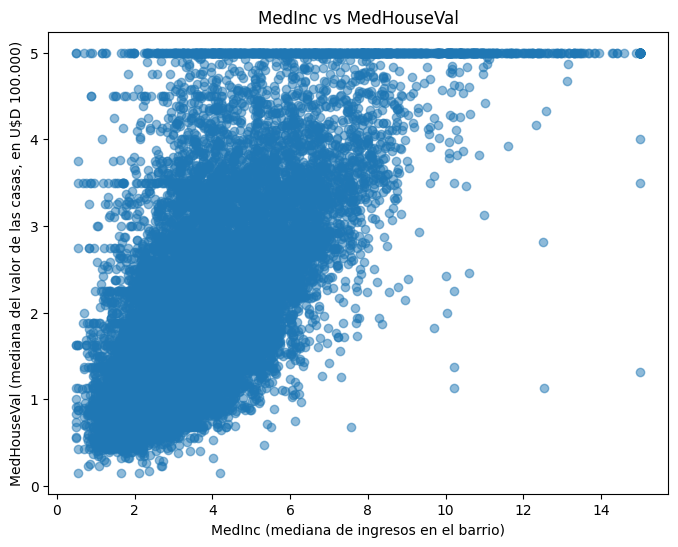

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(dataset.frame['MedInc'], dataset.frame['MedHouseVal'], alpha=0.5)
plt.xlabel('MedInc (mediana de ingresos en el barrio)')
plt.ylabel('MedHouseVal (mediana del valor de las casas, en U$D 100.000)')
plt.title('MedInc vs MedHouseVal')
plt.show()

Aunque hay una correlación de 0.69 entre ```MedInc``` y ```MedHouseVal```, el scatter plot muestra una gran dispersión, especialmente en valores altos de ```MedInc```. Se ve que en las casas de U$D 500.000 hay medianas de ingresos que oscilan practicamente por todo el rango, un comportamiento bastante extraño y que estaría bueno que investiguemos un poco más, pero que a propósito vamos a ignorar ahora.

### 2.2 - Ajustemos un modelo de regresión lineal simple

Como vimos en la teoría, la regresión lineal es una técnica estadística utilizada para modelar la relación entre una variable dependiente (o variable objetivo) y una o más variables independientes (o predictores). En el contexto más simple, la regresión lineal simple, se estudia la relación entre una sola variable independiente y la variable dependiente. La regresión lineal múltiple extiende esta idea para incluir múltiples predictores. Para ir construyendo sobre bases sólidas, arrancamos primero por la simple, y luego pasamos a la múltiple.

La idea central de la regresión lineal es encontrar la mejor recta (o plano, en el caso de trabajar con múltiples predictores) que explique la relación entre las variables. Esta recta se construye de tal forma que minimice la distancia entre los puntos observados y los puntos estimados por el modelo, utilizando un criterio de minimización de los errores cuadrados. A esos errores cuadrados los llamados "residuos", y los representamos con la letra griega $\epsilon$.

En una regresión lineal simple, la relación entre el valor de la variable dependiente $y$ y la variable independiente $x$ para una muestra $i$-ésima se representa mediante la ecuación:

$y_i = \beta_0 + \beta_1 x_i + \epsilon_i$,

donde:

- $y$ es el valor de la variable dependiente (lo que queremos predecir o explicar, la variable respuesta),
- $x$ es la variable independiente,
- $\beta_0$ es la ordenada al origen o constante del modelo, que representa el valor de $y$ cuando $x = 0$,
- $\beta_1$ es el coeficiente de $x$, que indica el cambio esperado en $y$ por cada unidad de cambio en $x$, y
- $\epsilon$ es, como dijimos antes, el término de error o residual, que captura la variación en $y$ no explicada por $x$.

Existen varias implementaciones de modelos lineales, sobre todo enfocadas en el desarrollo de predictores para aplicaciones de machine learning. En este caso vamos a trabajar con el paquete ```statsmodels``` de Python, que nos ofrece una implementación enfocada en problemas de análisis de datos. Dentro del subpaquete ```api```, disponemos de la librería ```sm```, que incluye varios modelos estándar. De ellos vamos a tomar ```OLS```, sigla en inglés de Ordinary Least Squares, o mínimos cuadrados ordinarios. Este es el modelo de regresión que vimos en la teoría.

Antes de avanzar, un detalle importante. Como estamos arrancando con un modelo de regresión lineal simple con una sola variable independiente, no es estrictamente necesario hacer algún tipo de estandarización de los datos. Pero luego, cuando avancemos combinando más de una variable, sí necesitamos hacerlo, para compensar los rangos disímiles entre diferentes variables.

Bueno, vamos a ajustar el primer OLS y a imprimir el ```summary``` de los resultados que obtenemos. Fíjense que, antes de avanzar, agregamos una constante para que podamos ajustar también la ordenada al origen:


In [ ]:
import numpy as np
import statsmodels.api as sm

# Separamos nuestra variable independiente
X = dataset.frame['MedInc']
# y nuestra variable objetivo (variable dependiente)
y = dataset.frame['MedHouseVal']

# Agregamos una constante como característica, para estimar la ordenada al origen
X = sm.add_constant(X)
# Ajustamos el modelo
model = sm.OLS(y, X).fit()
# Imprimimos el resumen de los resultados
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            MedHouseVal   R-squared:                       0.473
Model:                            OLS   Adj. R-squared:                  0.473
Method:                 Least Squares   F-statistic:                 1.856e+04
Date:                Thu, 06 Nov 2025   Prob (F-statistic):               0.00
Time:                        16:59:32   Log-Likelihood:                -25623.
No. Observations:               20640   AIC:                         5.125e+04
Df Residuals:                   20638   BIC:                         5.127e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4509      0.013     34.082      0.0

Esta tabla resume todo lo que necesitamos para, por un lado, interpretar el modelo, y por el otro poder discernir si los resultados que obtuvimos tienen o no sentido. Vamos a ir punto por punto desglosando lo que más nos interesa.

#### 2.2.1 - Coeficiente de determinación $R^2$:

El coeficiente de determinación $R^2$ es una medida estadística que indica qué proporción de la varianza en la variable dependiente (o respuesta) es explicada por el modelo de regresión lineal. De alguna forma, $R^2$ nos ayuda a entender entonces qué tan bien el modelo ajusta los datos.

Repasando un poco la matemática, acuérdense que:

$R^2 = 1 - \frac{\text{SSE}}{\text{SST}}$,

donde:

- $\text{SSE}$ (Suma de los Cuadrados de los Errores) es la suma de las diferencias al cuadrado entre los valores observados y los valores predichos por el modelo.

- $\text{SST}$ (Suma Total de los Cuadrados) es la suma de las diferencias al cuadrado entre los valores observados y la media de los valores observados.

En teoría, el valor de $R^2$ debería variar entre 0 y 1:

- Un valor de $R^2 = 1$ significa que el modelo explica el 100% de la varianza en la variable dependiente, es decir, que todos los puntos caen exactamente sobre la línea de regresión.

- Un valor de $R^2 = 0$ indica que el modelo no explica ninguna de la varianza en la variable dependiente, lo que significa que la variable independiente no tiene ninguna relación lineal con la variable dependiente.

En nuestro caso, vemos que obtuvimos un $R^2$ de 0.473. Esto indica que el modelo explica aproximadamente el 47.3% de la varianza de ```MedHouseVal``` a partir de ```MedInc```. Esto sugiere que ```MedInc``` es un predictor que puede andar bien, pero que aún falta mucha varianza sin explicar, posiblemente debido a otros factores no incluidos en el modelo, o a ruido que no hemos podido capturar.


#### 2.2.2 - Significancia del modelo (estadístico $F$):

El estadístico $F$ mide la significancia global del modelo. En términos conceptuales, nos dice si la varianza explicada por el modelo (gracias a la variable independiente ```MedInc```) es significativamente mayor que la varianza residual (o el "ruido" que no puede ser explicado por el modelo).

Les cuento de donde viene, pero como para que entiendan cómo se obtuvo. $F$ se calcula a partir de la relación entre:

- La varianza explicada (suma de cuadrados explicada o $\text{SSR}$, asociada con la variabilidad capturada por el modelo) y
- La varianza residual (suma de cuadrados residual o $\text{SSE}$, asociada con la variabilidad no explicada por el modelo).

Específicamente:

$F = \frac{\text{SSR}/ \text{df}_\text{modelo}}{\text{SSE}/\text{df}_\text{residual}}$

donde $\text{df}_\text{modelo}$ son los grados de libertad del modelo (número de predictores) y $\text{df}_\text{residual}$ son los grados de libertad de los errores (número de observaciones menos el número de predictores).

Si el valor de $F$ es alto, implica que la varianza explicada es considerablemente mayor que la varianza residual, lo que sugiere que el modelo es significativo. "Alto" es algo que por lo general es relativo entre una cosa y otra, así que lo que más nos va a interesar es el $p$-valor asociado al estadístico.

En este caso, el $p$-valor es recontra bajo ($p < 0.001$), lo que indica que el modelo en su conjunto es significativo. Esto implica que ```MedInc``` es útil para predecir ```MedHouseVal``` con una confianza estadística alta.


#### 2.2.3 - Análisis de los coeficientes del modelo lineal

Antes vimos que, al ajustar un modelo lineal simple, lo que estamos ajustando son los valores de los coeficientes $\beta_0$ y $\beta_1$. En este caso, cuando hicimos el ```summary``` no vimos ningún $\beta_i$, pero si a ```MedInc```, que es el coeficiente que está asociado a esa variable, y ```const```, que es la ordenada al origen del modelo lineal (el *intercept* en inglés). Mirémoslos uno a uno:

- El coeficiente de ```MedInc``` es 0.4179, lo que significa que por cada unidad que incrementemos la mediana de ingresos, el valor medio de las casas aumenta en esa proporción (recuerden igual que ```MedHouseVal``` está en unidades de U\$D 100.000, así que son unos U\$D 41.000).  Este coeficiente también es muy significativo ($p$ < 0.001), lo que confirma la fuerte asociación entre ambas variables. Si miramos el rango, vemos que no incluye al 0. Esto es una buena noticia.

- La constante es 0.4509, lo que representa el valor medio estimado de las casas cuando ```MedInc``` es cero. Aunque en un contexto real este valor no tenga un significado directo (porque una mediana de ingresos de cero es irreal), ayuda a ajustar la línea de regresión.

El análisis de estos coeficientes es justamente el valor principal que tiene la regresión usada en este contexto. **PERO no podemos asumirlos como verídicos hasta tanto no validemos el supuesto de normalidad de los residuos.**

#### 2.2.4 - Supuesto de normalidad de los residuos

La normalidad de los residuales es un supuesto clave en el análisis de regresión, ya que afecta la validez de las inferencias realizadas.

Tenemos varias formas de estudiar esto. La más natural para nosotros es hacerlo gráficamente representando los residuos en un QQ-plot, o usar un Shapiro-Wilk como para poder tener un $p$-valor. ¿Por qué es natural? Bueno, porque ya lo venimos haciendo en las unidades anteriores. Vayamos por ahí, primero, y después miremos una forma más rápida y directa.

Para recuperar los residuos, podemos usar:



In [ ]:
model.resid

,0
0,0.595723
1,-0.335330
2,0.036997
3,0.603676
4,1.363669
...,...
20635,-0.321965
20636,-0.748441
20637,-0.238351
20638,-0.384231


Fíjense que, por supuesto, tenemos un residuo asociado a cada muestra. Esto es porque justamente ahí estamos midiendo la diferencia entre lo que estimamos con el modelo lineal y lo que esperábamos obtener.

Hagamos un QQ-plot para ver la normalidad de estos residuos:

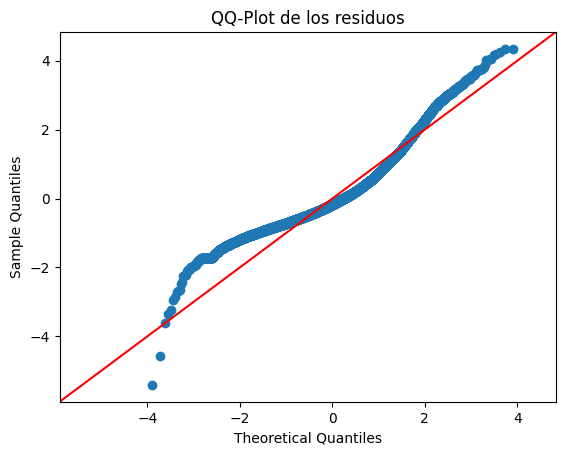

In [ ]:
# QQ-Plot
sm.qqplot(model.resid, line='45')
plt.title("QQ-Plot de los residuos")
plt.show()

Vemos que la silueta es bastante horrenda: no tenemos una semejanza a la recta de la diagonal, por lo que todo parece indicar que los residuos no respetan una distribución normal.

Chequeemos si Shapiro-Wilk coincide con esto que observamos recién:

In [ ]:
from scipy.stats import shapiro

# aplicamos Shapiro-Wilk sobre los residuos
_, p = shapiro(model.resid)
print("p = %.4f" % (p))
# comparamos con el alpha
alpha = 0.05
if p > alpha:
    print("Se distribuyen normal (falló en rechazarse la hipótesis nula)")
else:
    print('No se distribuyen normal (se rechazó la hipótesis nula)')

p = 0.0000
No se distribuyen normal (se rechazó la hipótesis nula)


/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 20640.
  res = hypotest_fun_out(*samples, **kwds)


El $p$-valor dio súper bajo, por lo que es claro que estamos rechazando la hipótesis nula acerca de la normalidad de los datos. A propósito, fíjense que scistats nos tiró un warning indicando que el $p$-valor puede no ser del todo preciso por el $N$ grande con el que estamos trabajando. No pasa nada porque ya hicimos un QQ-plot antes que nos tiró medio lo mismo, pero cuando vean este tipo de warnings... léanlos, al menos, no sea cosa que la pifien por esto.

Bueno, un bajón, ¿no? El modelo lineal parecía andar hermoso pero resulta que no se cumplían los supuestos, así que el análisis no es válido.

Les tengo otra noticia. Todo esto que hicimos recién del QQ-plot y del Shapiro-Wilk nos lo podíamos ahorrar, jeje. ¿Por qué? Bueno, porque el ```summary``` de Statsmodel nos acorta el camino brindándonos los resultados de dos tests, el de Omnibus y el de Jarque-Bera, que justamente evalúan si los residuales de la regresión se distribuyen normalmente, pero desde criterios diferentes.

Recuperemos el summary así no hay que scrollear hasta arriba y analicémoslo:


In [ ]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            MedHouseVal   R-squared:                       0.473
Model:                            OLS   Adj. R-squared:                  0.473
Method:                 Least Squares   F-statistic:                 1.856e+04
Date:                Thu, 06 Nov 2025   Prob (F-statistic):               0.00
Time:                        16:59:33   Log-Likelihood:                -25623.
No. Observations:               20640   AIC:                         5.125e+04
Df Residuals:                   20638   BIC:                         5.127e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4509      0.013     34.082      0.0

El **test de Omnibus** y el **test de Jarque-Bera** combinan dos aspectos estadísticos de los datos:

* Asimetría (skewness): indica si los residuales tienden a estar más hacia un lado (derecha o izquierda) de la distribución.
* Curtosis: mide si los datos tienen "colas" más pesadas o ligeras que una distribución normal.

El estadístico Omnibus analiza si hay desviaciones significativas en la asimetría y curtosis con respecto a la normalidad. Un $p$-valor bajo ($p < 0.05$) sugiere que los residuos no son normales. Lo tenemos escrito junto a ```Prob(Omnibus)```, y fíjense que es justamente lo que estamos viendo en este caso, y que a su vez va en línea con lo que habíamos visto antes con el test de Shapiro-Wilk y el QQ-plot. El test de Jarque-Bera también estudia la asimetría y la curtosis, pero usa una metodología diferente. Su $p$-valor está marcado como ```Prob(JB)```, y también es bajo.

Ya que estamos, grafiquemos el histograma de los residuos para estudiar visualmente estas diferencias en asimetría y curtosis respecto a la distribución normal:

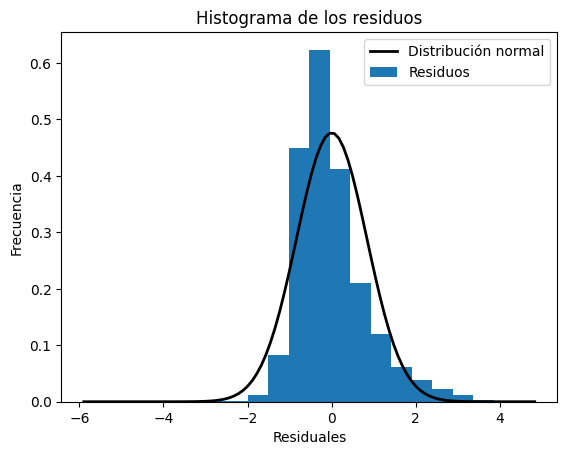

In [ ]:
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import norm

# Histograma de residuos
plt.hist(model.resid, bins=20, density=True)
# Ajustamos una curva normal a esos residuos
mu, std = norm.fit(model.resid)
# Graficamos la curva de la distribución normal
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'k', linewidth=2)

plt.xlabel("Residuales")
plt.ylabel("Frecuencia")
plt.title("Histograma de los residuos")
plt.legend(["Distribución normal", "Residuos"])
plt.show()


Se ve que aunque hay una silueta "acampanada", tenemos un desplazamiento leve hacia valores negativos, y una cola (la de la izquierda) bastante disimil respecto a una distribución normal. Tiene sentido, entonces, que los tests nos hayan dicho que no hay normalidad de residuos.

Pasando en limpio, pues. Los resultados de las pruebas Omnibus y Jarque-Bera, entonces, indican que los residuales no siguen una distribución normal (p < 0.001 en ambos casos). **Esto puede afectar la validez de las inferencias que hicimos en 2.2.1, 2.2.2 y 2.2.3.**

Último punto sobre normalidad de residuos. Otra forma de estudiar la validez del modelo es representando gráficamente los valores ajustados por el modelo vs. los residuos. Deberíamos observar un comportamiento "en banda" alrededor del 0, sin demasiados errores por encima o debajo del 3 y el -3, respectivamente (porque en una normal estándar los valores por fuera del intervalo [-3, 3] son muy poco frecuentes). Si observamos un patrón diferente a eso, entonces estamos vulnerando alguno de los supuestos:


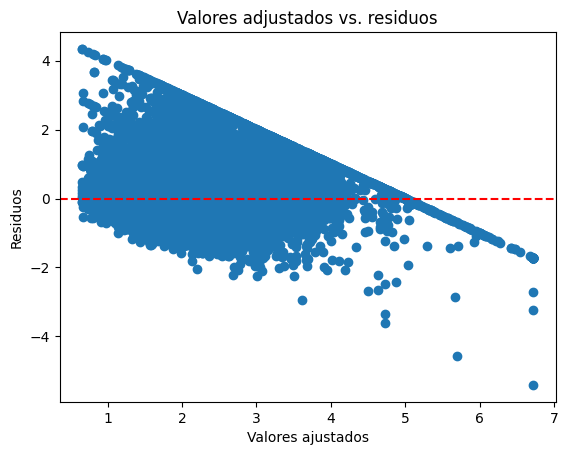

In [ ]:
plt.scatter(model.fittedvalues, model.resid)
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Valores adjustados vs. residuos")
plt.axhline(0, color='red', linestyle='--')
plt.show()

Y acá vemos claramente que ese comportamiento en banda no existe, y además vemos esa raya oblicua decreciente que, me la juego se asocia a esos valores saturados que vimos antes en el scatter plot.

#### 2.2.5 - Autocorrelación de los residuales y el estadístico de Durbin-Watson

La autocorrelación de los residuales ocurre cuando los errores de una observación están correlacionados con los errores de otras observaciones cercanas, lo cual puede ser problemático. Este fenómeno es común en datos de series temporales o datos espaciales, donde las observaciones están naturalmente ordenadas o relacionadas.

El estadístico de Durbin-Watson mide la presencia de autocorrelación en los residuos de un modelo de regresión. Su rango es entre 0 y 4, y podemos interpretarlo más o menos así:

- Un valor cercano a 2 indica que no hay autocorrelación significativa.
- Valores menores a 2 sugieren autocorrelación positiva (los errores tienden a estar relacionados de forma similar).
- Valores mayores a 2 sugieren autocorrelación negativa (los errores alternan en signo entre observaciones).

Recordemos cuántos nos dio a nosotros:

In [ ]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            MedHouseVal   R-squared:                       0.473
Model:                            OLS   Adj. R-squared:                  0.473
Method:                 Least Squares   F-statistic:                 1.856e+04
Date:                Thu, 06 Nov 2025   Prob (F-statistic):               0.00
Time:                        16:59:33   Log-Likelihood:                -25623.
No. Observations:               20640   AIC:                         5.125e+04
Df Residuals:                   20638   BIC:                         5.127e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4509      0.013     34.082      0.0

En este caso, un valor de 0.655 indica una autocorrelación positiva, lo que puede implicar que los errores no son completamente independientes entre sí. En un contexto de datos espaciales (como los datos de vivienda de California), esto podría deberse a patrones geográficos no modelados adecuadamente.

#### 2.2.6 - Análisis de AIC y BIC

¿Se acuerdan que en la teoría hablamos del concepto de **parsimonia**? Bueno, si tenemos 2 modelos y queremos elegir cuál es el mejor/más adecuado para nuestros datos, podemos usar los valores de AIC y BIC para hacerlo, porque comparan modelos según su complejidad.

El *Akaike Information Criterion* (AIC) penaliza la complejidad del modelo, buscando un equilibrio entre ajuste y simplicidad. Un AIC más bajo indica un mejor modelo, dado que explica bien los datos sin ser innecesariamente complejo. No viene al caso, pero por si les interesa, se define como:

$\text{AIC} = 2k - 2 \ln(L)$,

donde $k$ es el número de parámetros del modelo y $L$ es la verosimilitud del modelo. Esa $L$ está dada por la probabilidad conjunta de observar los datos dados los parámetros del modelo.

Por otro lado, el *Bayesian Information Criterion* (BIC) es muy parecido al AIC, pero con una penalización mayor por la cantidad de parámetros, lo que hace que BIC prefiera modelos incluso más simples que los que seleccionaríamos con AIC. Como en el caso anterior, un BIC más bajo indica un mejor modelo. Se calcula como:

$\text{BIC} = k \ln(n) − 2 \ln(L)$,

donde $n$ es el número de observaciones que usamos para ajustar el modelo.

En este caso, ambos valores de AIC y BIC son relativamente altos, a pesar de que estamos usando una única variable independiente. Esto puede deberse a que las estimaciones de $L$ sean erroneas producto de la no normalidad de los supuestos.

### 2.3 - Saquemos algunas conclusiones de nuestro análisis anterior

Vemos que a pesar de haber obtenido un valor de $R^2$ diferente de cero, y bastante alto (cerca de 0.5), e incluso a pesar de que el $p$-valor del modelo sea significativo, la violación de los supuestos nos obliga a descartar la hipótesis de usar ```MedInc``` como predictor de ```MedHouseVal```.

¿Podremos mejorar esto si usamos más variables? Vayamos por ahí.

## 3 - ¿Podremos predecir mejor  ```MedHouseVal``` si incorporamos más variables?

#### 3.1 - Análisis exploratorio

Vimos antes que la autocorrelación de los residuos sugiere que puede haber alguna relación entre las muestras que tenemos para el ajuste del modelo. Normalmente estas relaciones suelen tener que ver con tiempo, pero en este caso tenemos datos geográficos, así que tal vez exista algún tipo de relación espacial entre las muestras.

Contribuyendo a ese mismo análisis, recordemos que habíamos visto una corelación importante entre la latitud y la longitud, también. ¿Qué pasa si graficamos latitud y longitud vs. ```MedHouseVal```?

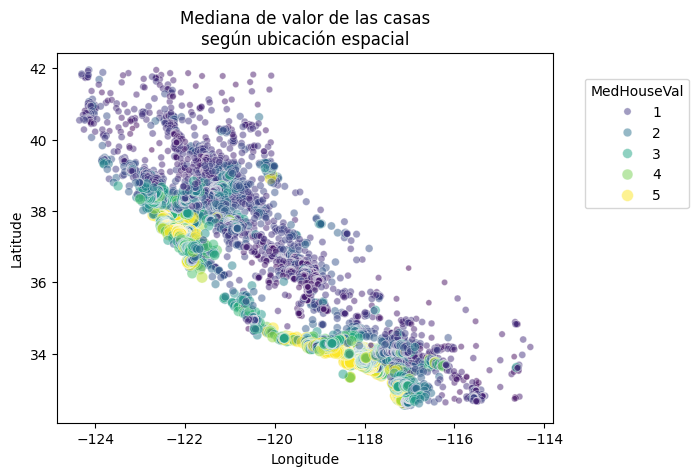

In [ ]:
import seaborn as sns

sns.scatterplot(data=dataset.frame, x="Longitude", y="Latitude",
                size="MedHouseVal", hue="MedHouseVal",
                palette="viridis", alpha=0.5)
plt.legend(title="MedHouseVal", bbox_to_anchor=(1.05, 0.95),
           loc="upper left")
_ = plt.title("Mediana de valor de las casas\nsegún ubicación espacial")

Fíjense que en esta gráfica vemos principalmente dos regiones con precios caros, que están relativamente cerca de las modas que habíamos observado en nuestro análisis por histograma. Comparemos esa gráfica con el mapa de California:

<img src="https://ontheworldmap.com/usa/state/california/map-of-california.jpg" alt="drawing" width="500"/>

Fíjense que vemos que la cercanía a la costa pareciera tener una relación con el precio de las casas, pero que además las regiones más concentradas parecieran corresponder con las zonas aledañas a San Francisco (al norte) y Los Ángeles/San Diego (al sur). También hay otro pico muy chiquito cerca de San Francisco, que puede corresponderse con la región de Sacramento.

Esto en principio sugiere que la latitud y la longitud podrían servirnos para discernir mejor los precios de las viviendas.

Y ya que estoy, me pregunto... ¿habrá alguna relación entre la mediana de ingresos y la ubicación de cada región? Porque en ese caso entonces podríamos combinar las variables para descubrir patrones nuevos. Como con la correlación no lo podemos estudiar (porque analizamos una variable contra otra, no dos contra una), podríamos repetir la misma lógica que en el plot anterior y hacer el análisis gráfico:





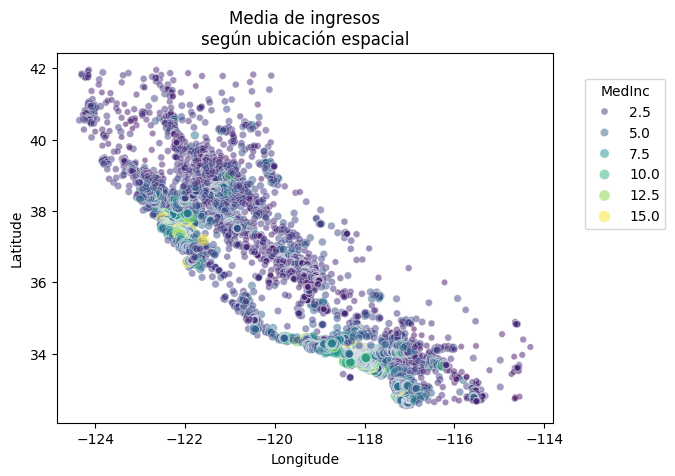

In [ ]:
import seaborn as sns

sns.scatterplot(data=dataset.frame, x="Longitude", y="Latitude",
                size="MedInc", hue="MedInc",
                palette="viridis", alpha=0.5)
plt.legend(title="MedInc", bbox_to_anchor=(1.05, 0.95),
           loc="upper left")
_ = plt.title("Media de ingresos\nsegún ubicación espacial")

Vemos que aunque las relaciones no son tan obvias como antes, se ve que las zonas vinculadas con estas regiones más populares/pobladas tienen valores de ```MedInc``` más grandes.

Evidentemente, entonces, ya en la latitud y la longitud tenemos información adicional que antes estábamos despreciando. ¿Cómo podemos saber si no estábamos desperdiciando otra información valiosa de las otras características? No queda otra: repitamos la regresión pero con todas nuestras características.

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Separar la variable objetivo (MedHouseVal) de las variables predictoras
X = dataset.frame.drop('MedHouseVal', axis=1)
y = dataset.frame['MedHouseVal']

# Estandarizar las variables predictoras
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# Metamoslo en un dataframe así no perdemos los nombres de las columnas
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

### 3.2 - Preprocesemos los datos para ajustar el modelo

Ahora sí estamos trabajando con más de una variable, así que vamos a necesitar estandarizar. Hagámoslo!

Revisemos si las estandarizaciones funcionaron correctamente:

In [ ]:
import pandas as pd

# Imprimir las medias y desviaciones estándar antes del escalado
print("Medias y desviaciones estándar antes del escalado:")
print(pd.DataFrame(X).describe().loc[['mean', 'std']])

# Imprimir las medias y desviaciones estándar después del escalado
print("\nMedias y desviaciones estándar después del escalado:")
print(pd.DataFrame(X_scaled_df).describe().loc[['mean', 'std']])

Medias y desviaciones estándar antes del escalado:
        MedInc   HouseAge  AveRooms  AveBedrms   Population   AveOccup  \
mean  3.870671  28.639486  5.429000   1.096675  1425.476744   3.070655   
std   1.899822  12.585558  2.474173   0.473911  1132.462122  10.386050   

       Latitude   Longitude  
mean  35.631861 -119.569704  
std    2.135952    2.003532  

Medias y desviaciones estándar después del escalado:
            MedInc      HouseAge      AveRooms     AveBedrms    Population  \
mean  6.609700e-17  5.508083e-18  6.609700e-17 -1.060306e-16 -1.101617e-17   
std   1.000024e+00  1.000024e+00  1.000024e+00  1.000024e+00  1.000024e+00   

          AveOccup      Latitude     Longitude  
mean  3.442552e-18 -1.079584e-15 -8.526513e-15  
std   1.000024e+00  1.000024e+00  1.000024e+00  


Efectivamente, vemos que las medias son cercanas a 0 y los desvíos cercanos a 1. Así que diez puntos, ya podemos avanzar y ajustar el regresor!

### 3.3 - Ajustemos ahora el modelo de regresión lineal multiple

En la regresión lineal múltiple, donde se incluyen múltiples variables predictoras, el modelo se extiende a:

$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + ... + \beta_p x_p \epsilon$,

donde:

- $x_1, x_2, \dots, x_p$ son las variables independientes.
- $\beta_1, \beta_2, \dots, \beta_p$ son los coeficientes asociados a cada variable independiente.

La regresión lineal múltiple nos permite evaluar cómo cada una de las variables independientes afecta la variable dependiente, controlando el efecto de las demás. Esto es útil cuando queremos entender el impacto combinado de varios factores en la variable de interés, como en este caso. Ajustemos el modelo y revisemos su summary, paso a paso:

In [ ]:
# Agregamos una constante como característica, para estimar la ordenada al origen
X_scaled_df_ = sm.add_constant(X_scaled_df)
# Ajustamos el modelo
model = sm.OLS(y, X_scaled_df_).fit()
# Imprimimos el resumen de los resultados
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            MedHouseVal   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                     3970.
Date:                Thu, 06 Nov 2025   Prob (F-statistic):               0.00
Time:                        16:59:37   Log-Likelihood:                -22624.
No. Observations:               20640   AIC:                         4.527e+04
Df Residuals:                   20631   BIC:                         4.534e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.0686      0.005    410.326      0.0

Ahora tenemos muchos coeficientes más, y varias cosas nuevas para estudiar. Vamos paso a paso.

#### 3.3.1 - Coeficiente de determinación $R^2$:

Vemos que el coeficiente de determinación en este caso es 0.606, contra 0.473 que teníamos antes. Esto implica que estamos ajustando mejor que como lo hacíamos antes, porque estamos explican un 60.6% de la variación en ```MedHouseVal```, cuando antes solamente capturábamos el 47.3%.

Esta mejora sugiere, entonces, que estas variables adicionales realmente aportan información útil al modelo, y que ayudan a capturar mejor la variabilidad en la mediana de valor de las casas.

#### 3.3.2 - Significancia del modelo (estadístico $F$):

Vemos que el valor del estadístico F se redujo (antes era 18560, ahora es 3970), pero lo que más nos interesa es estudiar el $p$-valor, que sigue siendo bajo ($p < 0.001$). Esto indica que el modelo nuevo también es significativo en su conjunto.

#### 3.3.3 - Análisis de los coeficientes del modelo lineal

Cada una de las variables incluidas ahora tiene un coeficiente estimado, que indica su contribución al valor de ```MedHouseVal```, controlando por las demás variables. Analicemos algunos puntos específicos:

* ```MedInc``` sigue siendo una variable importante, con un coeficiente positivo de 0.8296, indicando que aún es un predictor fuerte.

* ```Latitude``` y ```Longitude``` también son predictores significativos, lo cual refuerza nuestra hipótesis tal y como observamos en las gráficas anteriores.

* ```AveRooms``` y ```AveBedrms``` tienen coeficientes negativos y positivos, respectivamente, lo que implica que la relación entre el número promedio de habitaciones y dormitorios con el valor de la casa es compleja.

* ```Population``` y ```HouseAge``` no parecen contribuir demasiado, por lo que a lo mejor podrían eliminarse del modelo.



#### 3.3.4 - Supuesto de normalidad de los residuos

Los test Omnibus y de Jarque-Bera siguen indicando que los residuos no son normales ($p < 0.001$). Otra vez una mala noticia. Hagamos un QQ-plot para ver qué onda:

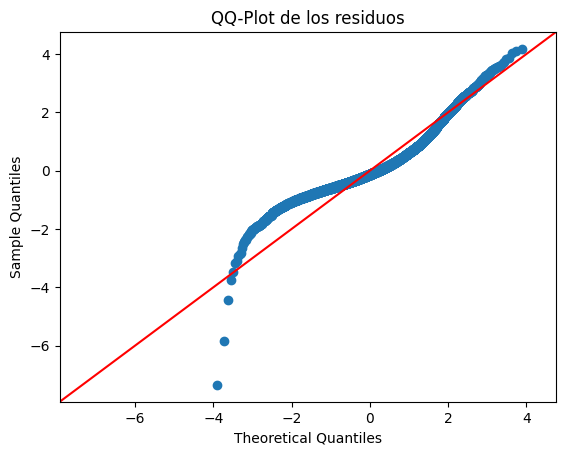

In [ ]:
# QQ-Plot
sm.qqplot(model.resid, line='45')
plt.title("QQ-Plot de los residuos")
plt.show()

Se ve bastante feo otra vez. ¿Qué pasa si usamos Shapiro-Wilk?

In [ ]:
from scipy.stats import shapiro

# aplicamos Shapiro-Wilk sobre los residuos
_, p = shapiro(model.resid)
print("p = %.4f" % (p))
# comparamos con el alpha
alpha = 0.05
if p > alpha:
    print("Se distribuyen normal (falló en rechazarse la hipótesis nula)")
else:
    print('No se distribuyen normal (se rechazó la hipótesis nula)')

p = 0.0000
No se distribuyen normal (se rechazó la hipótesis nula)


/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 20640.
  res = hypotest_fun_out(*samples, **kwds)


Sí, da horrible, no tenemos normalidad de residuos. Miremos si hay comportamiento en banda o no:

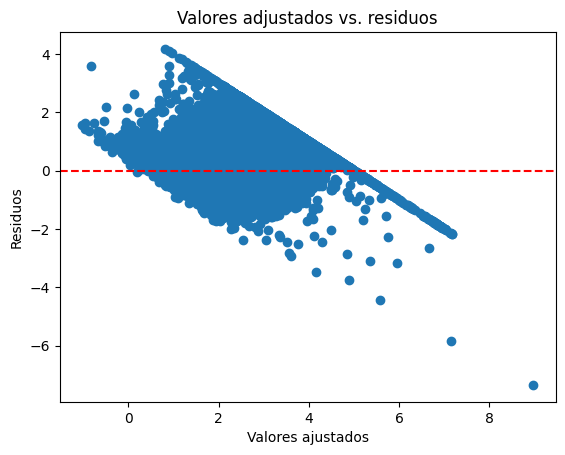

In [ ]:
plt.scatter(model.fittedvalues, model.resid)
plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Valores adjustados vs. residuos")
plt.axhline(0, color='red', linestyle='--')
plt.show()

Otra vez vemos esa diagonal y un patrón bastante feo. Evidentemente sigue habiendo un error sistemático que no estamos pudiendo capturar con el modelo lineal. Grafiquemos la distribución así vemos qué onda:

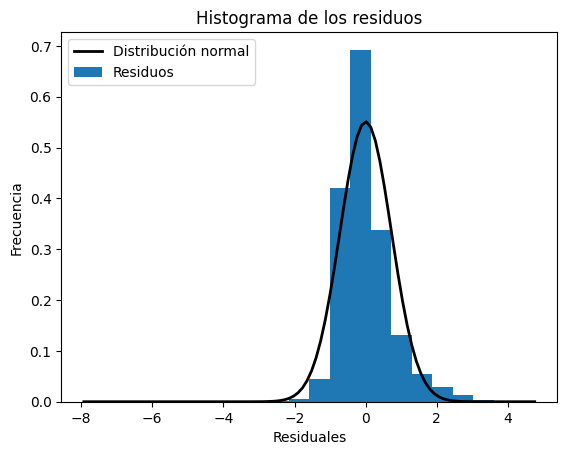

In [ ]:
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import norm

# Histograma de residuos
plt.hist(model.resid, bins=20, density=True)
# Ajustamos una curva normal a esos residuos
mu, std = norm.fit(model.resid)
# Graficamos la curva de la distribución normal
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mu, std)
plt.plot(x, p, 'k', linewidth=2)

plt.xlabel("Residuales")
plt.ylabel("Frecuencia")
plt.title("Histograma de los residuos")
plt.legend(["Distribución normal", "Residuos"])
plt.show()


Bueno, esta distribución se parece un poco más a una normal, pero vemos que todavía no ajusta lo suficiente, así que es entendible que los tests estén fallando. Seguimos sin normalidad entre residuos.

#### 3.3.5 - Autocorrelación de los residuales y el estadístico de Durbin-Watson

El estadístico de Durbin-Watson es ahora 0.885, lo cual sigue sugiriendo una autocorrelación positiva entre los residuales, mayor que la del modelo anterior (donde era 0.655). Esto podría ser debido a que, aunque el modelo captura mejor algunas de las relaciones espaciales en los datos con las nuevas variables, queda mucha dependencia entre los residuos por capturar, producto de ese mismo error sistemático que vemos en la gráfica de valores ajustados vs. residuos.

#### 3.3.6 - Análisis de AIC y BIC

Finalmente, vemos que el AIC bajó de 51250 a 45270, y el BIC de 51270 a 45340. Esto puede parecer contraintuitivo ahora que tenemos tantas variables nuevas, ¿no? Bueno, pero no es tan así: recordemos que nuestros residuos están en una, así que probablemente ambas estimaciones sean malas.

Mi hipótesis es que la mejora puede deberse a que la silueta de los residuos se parece un poco más a la de una distribución normal, si la comparamos con lo que teníamos previamente, y que por ende tengamos un mejor ajuste de $L$ en las cuentas del AIC y BIC.

### 3.4 - Algunas conclusiones finales

Con este nuevo modelo vimos una mejora importante en el valor de $R^2$, que nos esperanzó con estar algo más cerca del modelo que estamos buscando, pero al estudiar otra vez la normalidad de los residuos, vimos que no se cumple ese supuesto y que, por ende, este nuevo modelo lineal puede estar ajustando un poco mejor, pero no tiene todo el poder descriptivo que esperábamos.

¿Qué podemos hacer para mejorarlo? Bueno, podríamos tratar de explorar en los datos si hay outliers o muestras ruidosas que estén produciendo estas malas predicciones. O simplemente podría ocurrir que la relación entre las variables independientes y la variable respuesta simplemente no sean lineales, y que estemos intentando usar una recta para ajustar alguna otra forma en el hiperespacio de características.

Normalmente en estos casos nos tiraríamos a probar algún método no lineal (van a ver varios en el curso de Inteligencia Artificial). Pero bueno, eso es para el futuro.

Los dejo que son las 9:11 de la mañana del día de la clase, y ya estoy llegando 11 minutos tarde a lo próximo que me toca hacer. Tremendo neurótico el pibe. ¡Saluditos!

